# CHLA-Z 5: How the platforms and the satellites compare

**Author:** Eli Holmes (NOAA)<br>
Last updated: November 25, 2026

> **What this notebook is.** A look at the released CHLA-Z tables, side by
> side for the three in situ platforms: BGC-Argo floats, OOI moorings and
> profilers, and IOOS gliders. Where and when each samples, how their
> profiles differ, how their surface chlorophyll compares with PACE, why the
> time of day matters, and how OLCI and PACE overlap. It is **not** a methods
> notebook (those are 01–04 and 06) and **not** model training. It only reads
> the tables in `datasets/chla_z/data/`; it runs in about 1.5 minutes.

| # | Notebook | |
|---|---|---|
| 1 | 01-argo-retrieval-qc | BGC-Argo retrieval, QC, depth bins |
| 2 | 02-ooi-retrieval-qc | OOI retrieval, QC, 3 h solar-time windows, Sauzède correction |
| 3 | 03-pace-matchups | PACE Rrs, chlor_a, Kd matchups |
| 4 | 04-olci-matchups | Sentinel-3 OLCI Rrs matchups |
| 5 | **05-compare-datasets** | how the platforms and satellites compare |
| 6 | 06-glider-retrieval-qc | glider selection, retrieval, QC, one profile per 3 h window |

The in situ and satellite chlorophyll estimates measure different things and
are not expected to agree. In situ CHLA is fluorescence from a sensor at one
point, converted to chlorophyll. PACE `chlor_a` is computed from the colour of
the water (Rrs band ratios) over a 4 km cell, weighted toward the first
optical depth. They are correlated, and the ways they differ are what a
model has to learn.

**How the three platforms are processed** (details in the methods notebooks):

| | BGC-Argo | OOI | Gliders |
|---|---|---|---|
| Row | one ascending profile | one instrument, 3 h solar-time window (all samples averaged) | one deployment, 3 h solar-time window (one glider profile kept) |
| CHLA | `CHLA_ADJUSTED` (dark and NPQ corrected, Roesler factor 2) | fluorometer / Sauzède ratio | fluorometer / Sauzède ratio; dark offset kept as a column, not subtracted |
| Where | open ocean, global | 7 arrays: US shelves, Station Papa, Irminger, Southern Ocean... | mostly US coasts and shelves, a few offshore |

In [1]:
import sys

if "../../../src" not in sys.path:
    sys.path.insert(0, "../../../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import chla_z_build as b

D = b.DATA_DIR
NAMES = {"argo": "Argo", "ooi": "OOI", "glider": "Glider"}
COLORS = {"argo": "tab:blue", "ooi": "tab:orange", "glider": "tab:green"}
UNIT = {"argo": "PLATFORM_NUMBER", "ooi": "instrument", "glider": "dataset_id"}


def standard(df, platform):
    # Common time / lat / lon / solar_hour columns for the three tables.
    if platform == "argo":
        df = df.rename(columns={"TIME": "time", "LATITUDE": "lat", "LONGITUDE": "lon"})
    df["time"] = pd.to_datetime(df["time"], utc=True)
    t = df["time"]
    df["solar_hour"] = (t.dt.hour + t.dt.minute / 60 + df["lon"] / 15.0) % 24
    if platform == "ooi":
        df["instrument"] = df["profile_id"].str.rsplit("_", n=1).str[0]
    return df


prof = {p: standard(pd.read_parquet(D / f"CHLA_{p}_profiles.parquet"), p) for p in b.PLATFORMS}


def surface_vs_pace(platform, drop_deep_offset=True):
    # Rows with positive in situ 0-10 m CHLA and PACE chlor_a, with log10
    # values and the bias log10(PACE) - log10(in situ). For gliders, the
    # deployments flagged for a deep (dark) offset are left out by default:
    # that is the QC step the flag is there for.
    df = standard(pd.read_parquet(D / f"CHLA_{platform}_profiles_plus_PACE.parquet"), platform)
    if platform == "glider" and drop_deep_offset:
        df = df[~df["deep_offset_flag"]]
    df = df[(df["CHLA_0_10"] > 0) & (df["pace_chlor_a"] > 0)].copy()
    df["log_insitu"] = np.log10(df["CHLA_0_10"])
    df["log_pace"] = np.log10(df["pace_chlor_a"])
    df["bias"] = df["log_pace"] - df["log_insitu"]
    return df


sp = {p: surface_vs_pace(p) for p in b.PLATFORMS}
pd.DataFrame({NAMES[p]: {"rows in table": len(prof[p]), "units": prof[p][UNIT[p]].nunique(),
                         "rows with 0-10 m CHLA and PACE chlor_a": len(sp[p]),
                         "units with a matchup": sp[p][UNIT[p]].nunique()}
              for p in b.PLATFORMS}).T

,rows in table,units,rows with 0-10 m CHLA and PACE chlor_a,units with a matchup
Argo,59583,907,9344,826
OOI,95770,30,10399,12
Glider,98659,280,19587,255


"Units" are floats (Argo), instruments (OOI) and deployments (gliders).
Rows of one unit are not independent: OOI and glider windows of one day
share a PACE pixel, and a glider's consecutive windows are a few km apart.
Glider rows with `deep_offset_flag` are left out of the PACE comparisons
below (section 6 shows what they do).

## 1. Where and when

The three platforms sample very different water. Argo is the open ocean,
OOI a handful of fixed sites, and the gliders mostly continental shelves and
slopes off the US coasts.

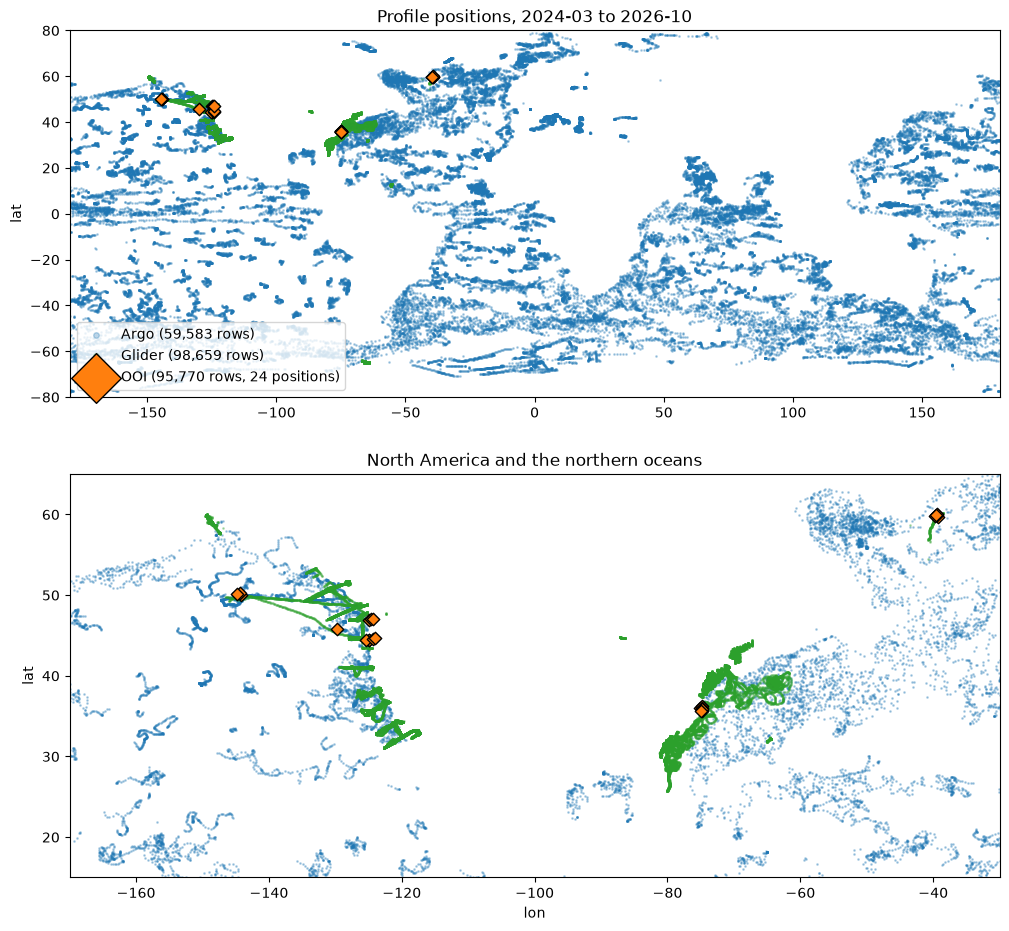

In [2]:
fig, axs = plt.subplots(2, 1, figsize=(12, 11), gridspec_kw={"height_ratios": [1, 1.1]})
for ax, (xl, yl) in zip(axs, [((-180, 180), (-80, 80)), ((-170, -30), (15, 65))]):
    for p in ("argo", "glider"):
        d = prof[p]
        ax.scatter(d["lon"], d["lat"], s=1, alpha=0.3, color=COLORS[p], label=f"{NAMES[p]} ({len(d):,} rows)")
    # OOI sites are fixed: draw each distinct position once, large, on top
    o = prof["ooi"][["lat", "lon"]].round(1).drop_duplicates()
    ax.scatter(o["lon"], o["lat"], s=40, marker="D", color=COLORS["ooi"], edgecolor="k",
               label=f"OOI ({len(prof['ooi']):,} rows, {len(o)} positions)")
    ax.set_xlim(xl); ax.set_ylim(yl); ax.set_ylabel("lat")
axs[0].legend(markerscale=4, loc="lower left"); axs[1].set_xlabel("lon")
axs[0].set_title("Profile positions, 2024-03 to 2026-10"); axs[1].set_title("North America and the northern oceans");

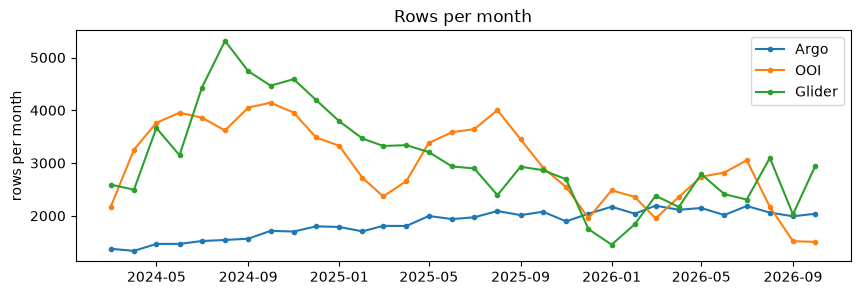

In [3]:
fig, ax = plt.subplots(figsize=(10, 3))
for p in b.PLATFORMS:
    m = prof[p].set_index("time").resample("MS").size()
    ax.plot(m.index, m.values, "-o", ms=3, color=COLORS[p], label=NAMES[p])
ax.set_ylabel("rows per month"); ax.legend()
ax.set_title("Rows per month");

Distance to shore is in the glider table (`shore_km`); for Argo and OOI it
is computed here the same way (Natural Earth coastline, `shore_distance_km`
in `chla_z_glider.py`), on positions rounded to 0.5°.

In [4]:
import chla_z_glider as g

shore = {}
for p in ("argo", "ooi"):
    # positions rounded to 0.5 deg (~50 km): enough for this comparison, and
    # ~10x fewer distances to compute than the ~60,000 Argo positions
    r = (prof[p][["lat", "lon"]] * 2).round() / 2
    pos = r.drop_duplicates().copy()
    pos["shore_km"] = g.shore_distance_km(pos.lat.to_numpy(), pos.lon.to_numpy())
    shore[p] = r.merge(pos, on=["lat", "lon"], how="left")["shore_km"]
shore["glider"] = prof["glider"]["shore_km"]
pd.DataFrame({NAMES[p]: shore[p].describe(percentiles=[0.1, 0.5, 0.9]) for p in b.PLATFORMS}).round(0).T[
    ["count", "10%", "50%", "90%"]].rename(columns=lambda c: c if c == "count" else f"{c} shore_km")

,count,10% shore_km,50% shore_km,90% shore_km
Argo,59583.0,106.0,522.0,1329.0
OOI,95770.0,42.0,73.0,458.0
Glider,98659.0,20.0,86.0,315.0


## 2. Profiles: depth coverage and shape

All three tables use the same 10 m bins, (A, B] from 0 to 200 m, so the
profiles can be compared directly. How many of the 20 bins a row fills:

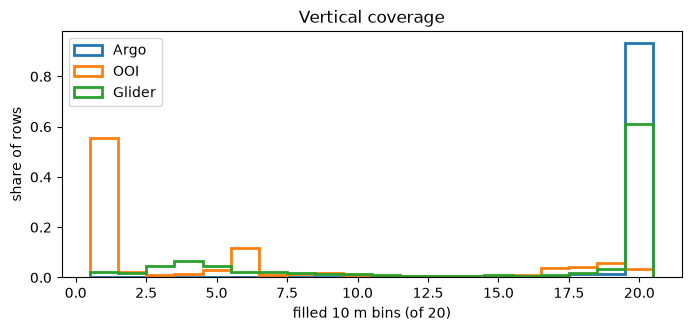

In [5]:
CH = b.CHLA_COLS
fig, ax = plt.subplots(figsize=(8, 3.2))
for p in b.PLATFORMS:
    n = prof[p][CH].count(axis=1)
    ax.hist(n, bins=np.arange(0.5, 21.5), density=True, histtype="step", lw=2, color=COLORS[p], label=NAMES[p])
ax.set_xlabel("filled 10 m bins (of 20)"); ax.set_ylabel("share of rows"); ax.legend()
ax.set_title("Vertical coverage");

Argo profiles nearly always fill all 20 bins. Most OOI rows fill **one**
bin: a fixed-depth instrument on a mooring is one bin per window; only the
profilers fill a column. Gliders sit in between: deep-water gliders fill the
column, shelf gliders stop at the bottom (30–80 m), and some windows keep a
shallow partial dive. A model that needs a full 0–200 m profile can use
Argo, the OOI profilers and the deep-water gliders; the surface bin is the
only one every platform shares.

The median profile, in rows that fill at least the top 10 bins (0–100 m),
normalised by each row's own 0–10 m value so the shapes can be compared:

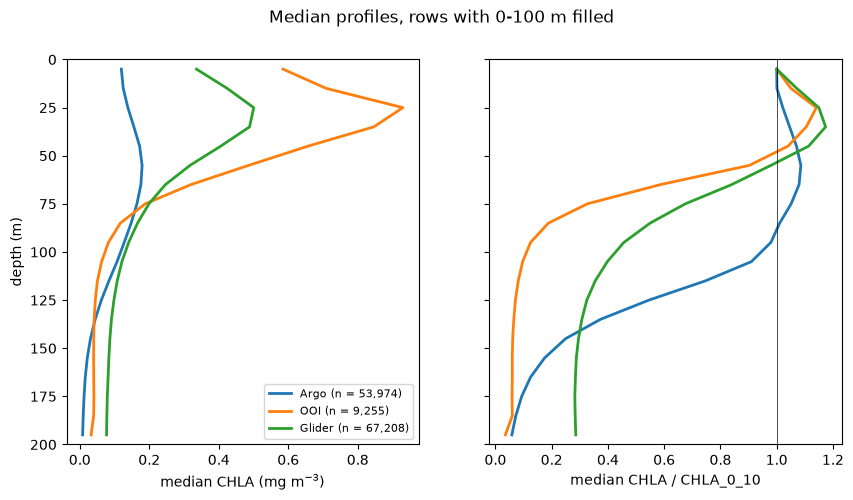

In [6]:
mid = np.arange(5, 200, 10)
fig, axs = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
for p in b.PLATFORMS:
    d = prof[p]
    d = d[d[CH[:10]].notna().all(axis=1) & (d["CHLA_0_10"] > 0.01)]
    axs[0].plot(d[CH].median(), mid, color=COLORS[p], lw=2, label=f"{NAMES[p]} (n = {len(d):,})")
    axs[1].plot(d[CH].div(d["CHLA_0_10"], axis=0).median(), mid, color=COLORS[p], lw=2)
axs[0].set_ylim(200, 0); axs[0].set_ylabel("depth (m)")
axs[0].set_xlabel("median CHLA (mg m$^{-3}$)"); axs[0].legend(fontsize=8)
axs[1].set_xlabel("median CHLA / CHLA_0_10"); axs[1].axvline(1, color="k", lw=0.5)
fig.suptitle("Median profiles, rows with 0-100 m filled");

The shapes differ in two ways. Argo's median profile has its maximum near
60 m and a nearly uniform upper 50 m: open ocean, a deep chlorophyll
maximum. OOI and the gliders have their maximum at 20–40 m and fall off
faster, as on a shelf. And below 150 m the gliders level off at about
0.08 mg m⁻³ (0.28 of their surface value), while Argo and OOI go to near
zero: that is the deep (dark) offset that the glider table keeps as
`dark_offset` but does not subtract (Argo's `CHLA_ADJUSTED` is dark
corrected).

Where the chlorophyll maximum sits (rows with 0–100 m filled): a
subsurface maximum is the rule in the open ocean (Argo) and much less common
in the mixed coastal water most gliders sample.

,rows,max in 0-10 m,max below 40 m,median depth (m)
Argo,56845.0,0.09,0.67,55.0
OOI,9269.0,0.14,0.29,25.0
Glider,67280.0,0.18,0.33,35.0


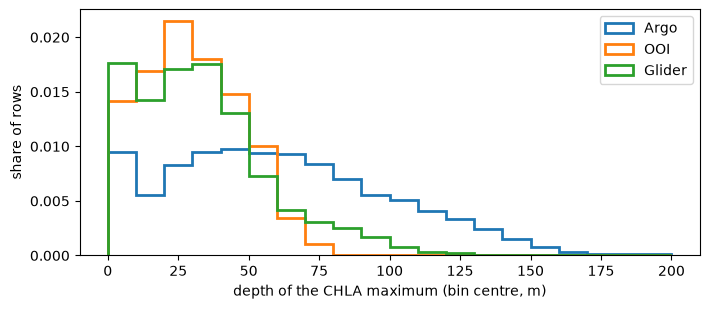

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.2))
zmax = {}
for p in b.PLATFORMS:
    d = prof[p]
    d = d[d[CH[:10]].notna().all(axis=1)]
    zmax[p] = mid[np.nanargmax(d[CH].to_numpy(float), axis=1)]
    ax.hist(zmax[p], bins=np.arange(0, 201, 10), density=True, histtype="step", lw=2,
            color=COLORS[p], label=NAMES[p])
ax.set_xlabel("depth of the CHLA maximum (bin centre, m)"); ax.set_ylabel("share of rows"); ax.legend();
pd.DataFrame({NAMES[p]: {"rows": len(z), "max in 0-10 m": np.mean(z == 5).round(2),
                         "max below 40 m": np.mean(z > 40).round(2), "median depth (m)": np.median(z)}
              for p, z in zmax.items()}).T

## 3. Surface chlorophyll: in situ vs PACE

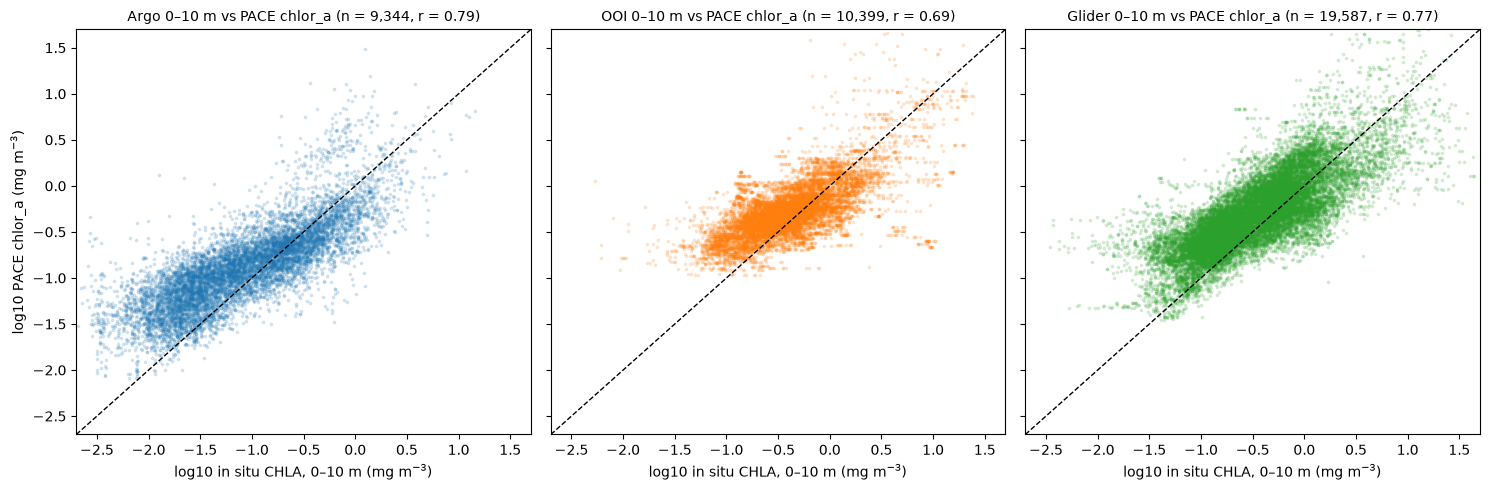

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, p in zip(axes, b.PLATFORMS):
    df = sp[p]
    ax.scatter(df["log_insitu"], df["log_pace"], s=3, alpha=0.15, color=COLORS[p])
    lims = [-2.7, 1.7]
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    r = np.corrcoef(df["log_insitu"], df["log_pace"])[0, 1]
    ax.set_title(f"{NAMES[p]} 0–10 m vs PACE chlor_a (n = {len(df):,}, r = {r:.2f})", fontsize=10)
    ax.set_xlabel("log10 in situ CHLA, 0–10 m (mg m$^{-3}$)")
axes[0].set_ylabel("log10 PACE chlor_a (mg m$^{-3}$)")
plt.tight_layout()

The median bias, log10(PACE) − log10(in situ), by in situ chlorophyll:

In [9]:
bins = [-3, -1.5, -1, -0.5, 0, 0.5, 1, 2]
pd.DataFrame({
    NAMES[p]: sp[p].groupby(pd.cut(sp[p]["log_insitu"], bins), observed=False)["bias"].median()
    for p in b.PLATFORMS
}).round(2).rename_axis("log10 in situ CHLA")

,Argo,OOI,Glider
log10 in situ CHLA,,,
"(-3.0, -1.5]",0.53,1.04,0.96
"(-1.5, -1.0]",0.27,0.49,0.44
"(-1.0, -0.5]",0.02,0.29,0.27
"(-0.5, 0.0]",-0.15,0.04,0.11
"(0.0, 0.5]",-0.29,-0.20,-0.11
"(0.5, 1.0]",-0.48,-0.30,-0.32
"(1.0, 2.0]",-0.35,-0.37,-0.61


The chlorophyll each platform samples, at the surface, in the matched rows:

In [10]:
pd.DataFrame({NAMES[p]: (10 ** sp[p]["log_insitu"]).describe(percentiles=[0.05, 0.5, 0.95])
              for p in b.PLATFORMS}).round(3)

,Argo,OOI,Glider
count,9344.000,10399.000,19587.000
mean,0.241,0.832,0.838
std,0.536,1.700,2.056
min,0.000,0.005,0.001
5%,0.009,0.089,0.052
50%,0.077,0.404,0.332
95%,0.956,2.596,2.810
max,14.292,24.307,43.733


All three show the familiar pattern: PACE reads higher than the in situ
sensor in clear, low-chlorophyll water and lower where chlorophyll is high.
The platforms sample different parts of that range. Argo floats are mostly
in the open ocean: half the matched profiles are below about 0.08 mg m⁻³ and
very few are above 1, so blooms are barely sampled. OOI and the gliders sit
around 0.3–0.4 mg m⁻³ with a long tail to 2–3 and above, so together they
fill in the coastal, higher-chlorophyll range Argo misses. In the bins
where they overlap, OOI and the gliders agree with each other (within about
0.1 log10 from 0.03 to 3 mg m⁻³) better than either agrees with Argo:
the bias is a property of the water type as much as of the platform.

## 4. Time of day: quenching in the in situ data

In bright light, phytoplankton shed absorbed energy as heat instead of
fluorescence (non-photochemical quenching, NPQ). A fluorometer near the
surface then reads low around midday. PACE is a daily composite with no
per-pixel overpass time, so the satellite side does not change with the
profile's time of day: any pattern in the bias by solar hour comes from the
in situ side.

Argo `CHLA_ADJUSTED` has an NPQ correction; OOI and the gliders have none.
First, when each platform samples:

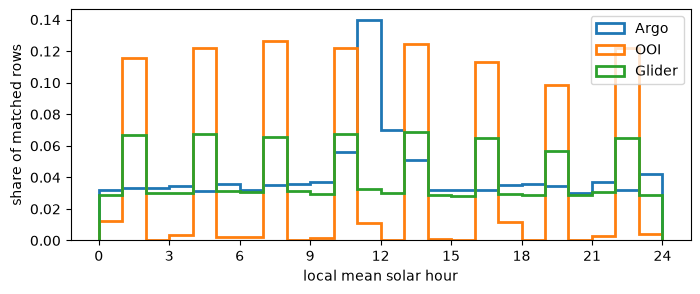

In [11]:
fig, ax = plt.subplots(figsize=(8, 3))
for p in b.PLATFORMS:
    ax.hist(sp[p]["solar_hour"], bins=np.arange(0, 25, 1), density=True, histtype="step", lw=2,
            color=COLORS[p], label=NAMES[p])
ax.set_xticks(range(0, 25, 3)); ax.set_xlabel("local mean solar hour"); ax.set_ylabel("share of matched rows")
ax.legend();

The median bias in 3 h bins of local mean solar time, with the
interquartile range:

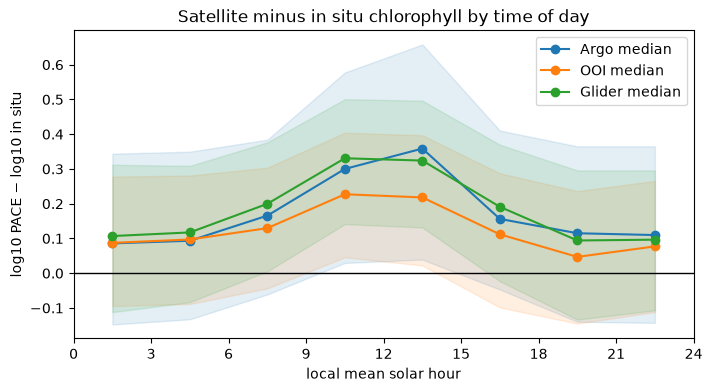

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
for p in b.PLATFORMS:
    df = sp[p]
    q = df.groupby((df["solar_hour"] // 3 * 3).astype(int))["bias"].quantile([0.25, 0.5, 0.75]).unstack()
    x = q.index + 1.5
    ax.plot(x, q[0.5], "-o", color=COLORS[p], label=f"{NAMES[p]} median")
    ax.fill_between(x, q[0.25], q[0.75], color=COLORS[p], alpha=0.12)
ax.axhline(0, color="k", lw=1)
ax.set_xticks(range(0, 25, 3))
ax.set_xlabel("local mean solar hour")
ax.set_ylabel("log10 PACE − log10 in situ")
ax.set_title("Satellite minus in situ chlorophyll by time of day")
ax.legend();

In [13]:
pd.DataFrame({NAMES[p]: sp[p].groupby((sp[p]["solar_hour"] // 3 * 3).astype(int))["bias"]
              .agg(["median", "count"]).stack()
              for p in b.PLATFORMS}).unstack().round(2)

Argo            OOI         Glider        
           median   count median   count median   count
solar_hour                                             
0            0.09   924.0   0.09  1334.0   0.11  2460.0
3            0.09   949.0   0.10  1326.0   0.12  2524.0
6            0.17   959.0   0.13  1340.0   0.20  2494.0
9            0.30  2172.0   0.23  1402.0   0.33  2531.0
12           0.36  1435.0   0.22  1306.0   0.32  2499.0
15           0.16   928.0   0.11  1308.0   0.19  2391.0
18           0.11   938.0   0.05  1035.0   0.09  2249.0
21           0.11  1039.0   0.08  1348.0   0.10  2439.0

All three platforms show the same shape. At night the median bias is about
0.1 log10; between 09 and 15 h solar time it is about 0.3–0.36 for Argo and
the gliders and about 0.22 for OOI. So relative to the satellite, the in
situ value at midday is roughly 40% (Argo, gliders) and 25% (OOI) lower
than at night. Three
independent data sets agree, and the Argo pattern is there even after its
NPQ correction.

The platforms sample the day differently. Argo floats surface on a
schedule, and many surface near local noon, so midday is over-represented in
the Argo table. OOI and glider rows are 3 h windows around the clock, so
every hour is about equally represented. This is why the tables carry the
profile time (and a model should carry `solar_hour`): it lets a model learn
the quenching effect instead of absorbing it as noise.

## 5. Water clarity

Is the bias also related to how clear the water is? To keep quenching out of
it, use only night-time rows (solar hour before 8 or after 16).
1/Kd(490) is roughly the depth (m) of the layer the satellite sees.

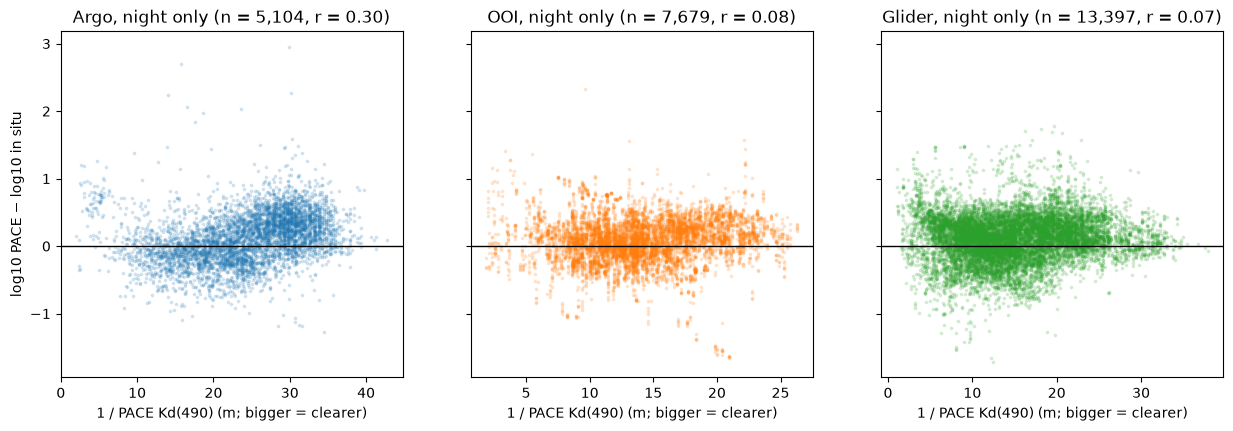

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, p in zip(axes, b.PLATFORMS):
    df = sp[p]
    night = df[~df["solar_hour"].between(8, 16) & df["pace_Kd_490"].notna()]
    ax.scatter(1 / night["pace_Kd_490"], night["bias"], s=3, alpha=0.15, color=COLORS[p])
    r = np.corrcoef(1 / night["pace_Kd_490"], night["bias"])[0, 1]
    ax.axhline(0, color="k", lw=1)
    ax.set_title(f"{NAMES[p]}, night only (n = {len(night):,}, r = {r:.2f})")
    ax.set_xlabel("1 / PACE Kd(490) (m; bigger = clearer)")
axes[0].set_ylabel("log10 PACE − log10 in situ");

For Argo the satellite reads higher in clearer water, which is the
low-chlorophyll pattern of section 3 seen through Kd (Kd and chlor_a are
themselves strongly related). The OOI sites and the gliders sample mostly
turbid, shallow-optical-depth water (1/Kd of 5–25 m) and show no trend.

## 6. Gliders: regions, the deep offset, and the coast

The gliders cover many regions, and the agreement with PACE is not the same
everywhere. Night-time median bias by region (night = solar hour outside
6–18 h, so quenching is small), all glider rows including the deep-offset
deployments:

In [15]:
gl = surface_vs_pace("glider", drop_deep_offset=False)
night = gl[~gl["solar_hour"].between(6, 18)]
reg = night.groupby("region").agg(rows=("bias", "size"), deployments=("dataset_id", "nunique"),
                                  median_bias=("bias", "median"),
                                  median_insitu=("CHLA_0_10", "median"),
                                  median_shore_km=("shore_km", "median"))
reg["PACE / in situ"] = 10 ** reg["median_bias"]
reg.sort_values("rows", ascending=False).round(2)

,rows,deployments,median_bias,median_insitu,median_shore_km,PACE / in situ
region,,,,,,
California Current,4818,54,0.07,0.33,67.30,1.18
Mid-Atlantic Bight and slope,3175,92,0.21,0.45,69.90,1.62
Pacific Northwest (OR/WA),1564,41,-0.19,1.07,84.20,0.64
South Atlantic Bight / off Hatteras,769,28,0.13,0.17,85.73,1.35
Gulf of Alaska / Bering,365,16,-0.52,2.23,93.31,0.30
Southern New England / Gulf of Maine,314,8,0.24,0.75,29.17,1.75
Open NW Atlantic (slope sea / Gulf Stream),269,5,0.26,0.09,479.63,1.83
British Columbia / Salish Sea,175,19,-0.38,2.07,66.91,0.41
Irminger / subpolar N Atlantic,102,5,-0.16,0.61,198.31,0.70


**The deep (dark) offset.** `deep_offset_flag` marks deployments whose
fluorometer reads > 0.2 below 300 m, mostly California Current Sprays. With
that offset in the in situ value, the satellite / in situ ratio should be
lower for flagged rows. Night-time rows, California Current only, so the
comparison is within one region:

In [16]:
cc = night[night["region"] == "California Current"]
cc.groupby("deep_offset_flag").agg(rows=("bias", "size"), deployments=("dataset_id", "nunique"),
                                   median_bias=("bias", "median"),
                                   median_dark_offset=("dark_offset", "median")).assign(
    **{"PACE / in situ": lambda x: (10 ** x["median_bias"]).round(2)}).round(3)

,rows,deployments,median_bias,median_dark_offset,PACE / in situ
deep_offset_flag,,,,,
False,2908,35,0.124,0.153,1.33
True,1910,19,-0.002,0.315,0.99


Within the California Current, the flagged deployments read about 0.3
below 300 m (vs 0.15 for the others), and their night-time PACE / in situ
ratio is about 1.0 instead of about 1.3: the in situ value carries the
offset, so it is about a third higher. This is why the flag is there; dropping
the flagged rows, or subtracting `dark_offset`, are both options for the QC
step.

By region the night-time bias ranges widely: PACE reads well below the
glider in Alaska, British Columbia and the Pacific Northwest, where the
gliders see 1–2 mg m⁻³ at the surface (the high-chlorophyll end of section
3), and above it on the East Coast shelves and offshore. A model trained on
gliders needs the region (or the water type) to absorb this.

**Near the coast.** PACE's atmospheric correction fails close to some
coasts: Rrs(442) near zero or negative and chlor_a far above the glider
value. The glider table keeps `shore_km` for this. Median bias by distance to
shore (all hours):

In [17]:
sb = pd.cut(gl["shore_km"], [0, 10, 25, 50, 100, 2000])
pd.DataFrame({"rows": gl.groupby(sb, observed=False).size(),
              "median bias": gl.groupby(sb, observed=False)["bias"].median().round(2),
              "share PACE chlor_a > 8": gl.groupby(sb, observed=False)["pace_chlor_a"]
              .apply(lambda s: (s > 8).mean()).round(3),
              "share Rrs(442) <= 0": gl.groupby(sb, observed=False)["pace_Rrs_442"]
              .apply(lambda s: (s <= 0).mean()).round(3)}).rename_axis("shore_km")

,rows,median bias,share PACE chlor_a > 8,share Rrs(442) <= 0
shore_km,,,,
"(0, 10]",844,0.30,0.095,0.098
"(10, 25]",3533,0.24,0.045,0.017
"(25, 50]",3281,0.20,0.012,0.008
"(50, 100]",8325,0.16,0.000,0.002
"(100, 2000]",7435,0.08,0.000,0.000


The near-shore failure shows up within ~25 km of the coast: about 5–10% of
those matchups have PACE chlor_a > 8 mg m⁻³, and in the first 10 km one in
ten has Rrs(442) ≤ 0. Beyond 50 km neither happens. The median bias also
falls with distance from shore (0.30 within 10 km, 0.08 beyond 100 km).

## 7. OLCI and PACE

The `_plus_OLCI` tables hold every profile on a day with an OLCI file, with
flags for whether it also has a PACE match. Through September 2026 (both
sensors available):

In [18]:
rows = {}
for platform in b.PLATFORMS:
    o = pd.read_parquet(D / f"CHLA_{platform}_profiles_plus_OLCI.parquet")
    o = o[o["olci_day"] < "20261001"]
    olci_ok = o[[f"olci_Rrs_{nm}" for nm in b.OLCI_BANDS]].notna().all(axis=1)
    rows[NAMES[platform]] = {"profiles": len(o),
                             "OLCI, all 11 bands": int(olci_ok.sum()),
                             "PACE Rrs": int(o["pace_Rrs_valid"].sum()),
                             "both": int((olci_ok & o["pace_Rrs_valid"]).sum()),
                             "either": int((olci_ok | o["pace_Rrs_valid"]).sum())}
pd.DataFrame(rows).T

,profiles,"OLCI, all 11 bands",PACE Rrs,both,either
Argo,57544,12535,9187,4935,16787
OOI,94265,23900,21823,13484,32239
Glider,95707,26848,24378,15576,35650


OLCI gives more valid matchups than PACE, and only part of each sensor's
valid profiles are valid in the other, so using both adds data. Part of the
difference is the matching rule, not the sensor: PACE uses a 24 h window
from the file's start time, OLCI the profile's UTC calendar day.

Where both are valid, the two sensors' Rrs at similar bands, for each
platform:

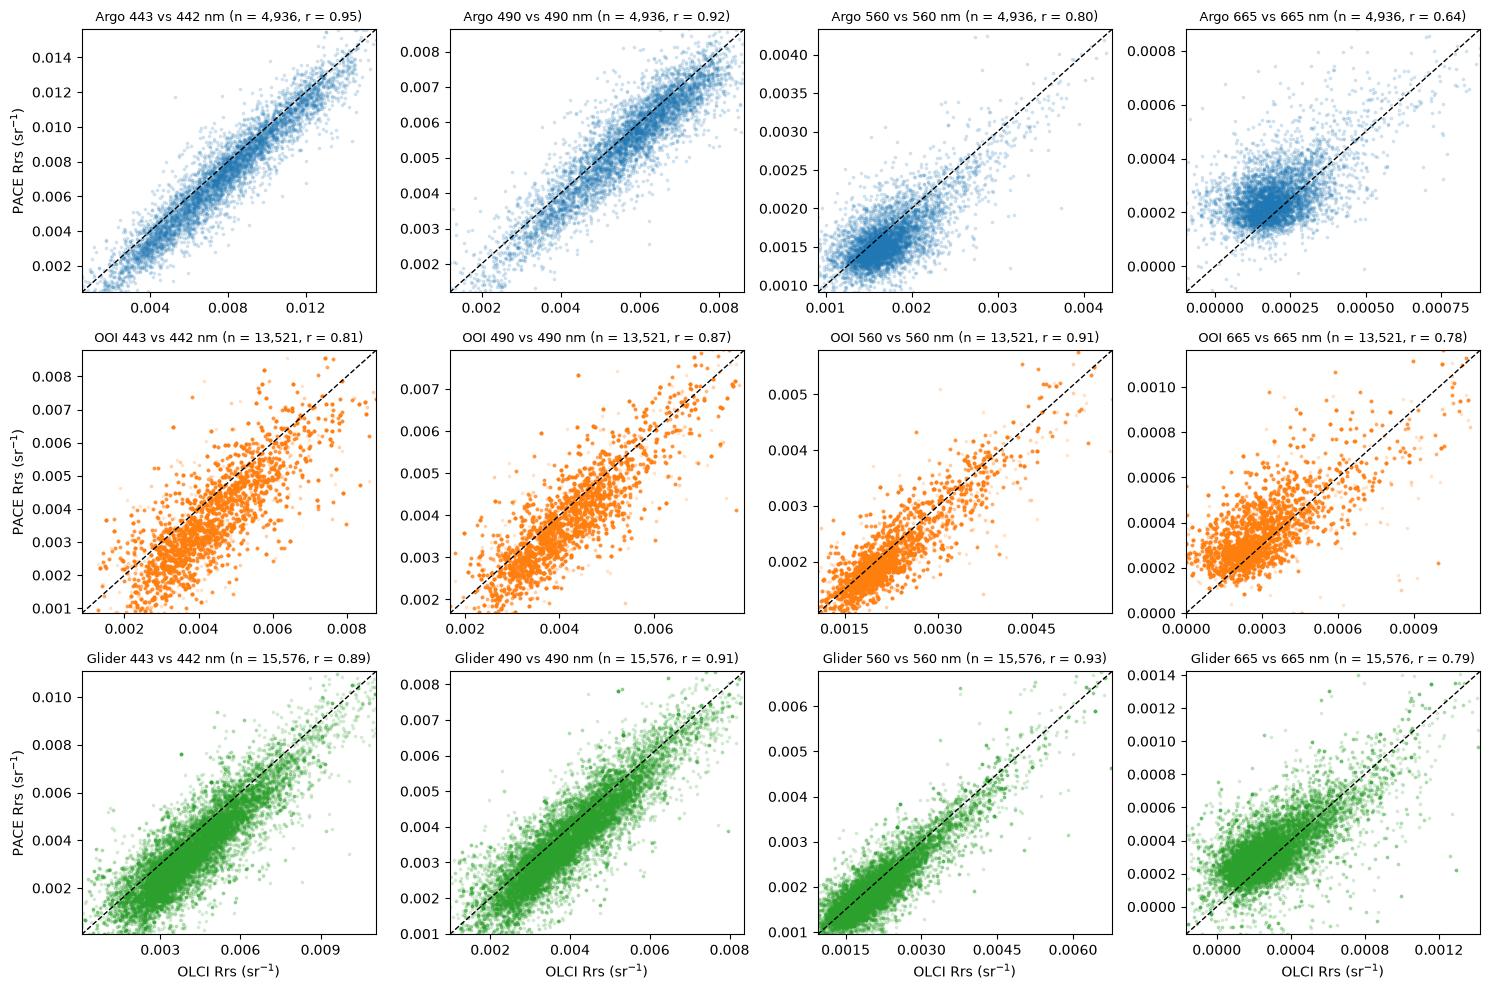

In [19]:
pairs = [(443, 442), (490, 490), (560, 560), (665, 665)]
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for row, p in zip(axes, b.PLATFORMS):
    o = pd.read_parquet(D / f"CHLA_{p}_profiles_plus_OLCI.parquet")
    pc = pd.read_parquet(D / f"CHLA_{p}_profiles_plus_PACE.parquet",
                         columns=["profile_id"] + [f"pace_Rrs_{nm}" for _, nm in pairs])
    both = o[o["pace_Rrs_valid"]].merge(pc, on="profile_id")
    for ax, (o_nm, p_nm) in zip(row, pairs):
        x, y = both[f"olci_Rrs_{o_nm}"], both[f"pace_Rrs_{p_nm}"]
        ok = x.notna() & y.notna()
        ax.scatter(x[ok], y[ok], s=3, alpha=0.15, color=COLORS[p])
        lo, hi = np.nanpercentile(np.r_[x[ok], y[ok]], [0.5, 99.5])
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        ax.xaxis.set_major_locator(plt.MaxNLocator(4))
        ax.set_title(f"{NAMES[p]} {o_nm} vs {p_nm} nm (n = {ok.sum():,}, "
                     f"r = {np.corrcoef(x[ok], y[ok])[0, 1]:.2f})", fontsize=9)
    row[0].set_ylabel("PACE Rrs (sr$^{-1}$)")
for ax in axes[-1]:
    ax.set_xlabel("OLCI Rrs (sr$^{-1}$)")
plt.tight_layout()

The match between the two sensors depends on the water. In the open ocean
(Argo) they agree best in the blue (r ≈ 0.95 at 443 nm) and least in the red
(r ≈ 0.6 at 665 nm), where Rrs is small. In the coastal water of OOI and the
gliders it is the other way round in part: the green (560 nm) agrees best
(r ≈ 0.9) and the blue less well (r ≈ 0.8–0.9), where atmospheric
correction near the coast is hardest.

## Where to go next

- How each table is made: notebooks 01–04 and 06, and `datasets/chla_z/README.md`.
- Rules and decisions behind the tables: `claude/notes/chla-z-rebuild-2026-11.md`
  (Argo, OOI) and `claude/notes/chla-z-glider.md` (gliders).
- When training, group train/test splits in space and time, not by row:
  windows of one OOI instrument-day or one glider day share a satellite
  pixel, and consecutive glider windows are a few km apart.
- For gliders, decide on `deep_offset_flag`, `scan_check` and a near-shore
  (`shore_km`) or Rrs-quality filter before training.

### Earlier notebooks

These notebooks replace `argopy.ipynb`, `ooi.ipynb` and `argo-matchups.ipynb`,
which built the tables before the build moved to `build.py`. They are kept
at the release tag
[`2026_11_23`](https://github.com/fish-pace/fish-pace-datasets/tree/2026_11_23/datasets/chla_z/notebooks),
or locally with `git checkout 2026_11_23 -- datasets/chla_z/notebooks/argopy.ipynb`.